# Character-Level CNN for Indonesian SMS Spam Detection
## 1. Environment Setup and Reproducibility Configuration
This notebook implements corpus auditing, template deduplication, grouped partitioning, training augmentation, model convergence, and ablation experiments for the proposed Character-Level Convolutional Neural Network (Char-CNN).

In [1]:
import os
import hashlib
import random
import string
import pickle
import warnings

SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
os.environ['TF_DETERMINISTIC_OPS'] = '1'
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from scipy.sparse.csgraph import connected_components
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score
)

import tensorflow as tf
from tensorflow.keras import regularizers
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.layers import (
    Input, Embedding, SpatialDropout1D, Conv1D, GlobalMaxPooling1D,
    Dense, Dropout, concatenate, Multiply
)
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42

def set_all_seeds(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)

set_all_seeds(SEED)

print(f"Python: {os.sys.version.split()[0]} | NumPy: {np.__version__} | Pandas: {pd.__version__}")
print(f"Scikit-Learn: {sklearn.__version__} | TensorFlow: {tf.__version__} | Seed: {SEED}")

Python: 3.13.18 | NumPy: 2.4.6 | Pandas: 2.2.3
Scikit-Learn: 1.6.1 | TensorFlow: 2.21.0 | Seed: 42


## 2. Corpus Provenance, Label Conflict Check, and Template Grouping
Raw entries are audited for missing or conflicting labels, mapped to their collection sub-sources, normalized to the 41-character vocabulary, and grouped into near-duplicate template clusters using character 3–5 gram cosine similarity ($\ge 0.80$).

In [2]:
df_raw = pd.read_excel('combined_dataset.xlsx', sheet_name='Sheet1')
missing_mask = df_raw['konten'].isna() | df_raw['spam'].isna()

df_clean = df_raw.dropna(subset=['konten', 'spam']).copy()
df_clean['konten'] = df_clean['konten'].astype(str)
df_clean['spam'] = df_clean['spam'].astype(str).str.strip().str.upper()
df_clean = df_clean[df_clean['spam'].isin(['SPAM', 'HAM'])].reset_index(drop=True)

df_clean['makna_clean'] = df_clean['makna'].fillna('UNSPECIFIED').astype(str).str.strip().str.upper()
df_clean['source_group'] = np.where(
    df_clean['makna_clean'] != 'UNSPECIFIED',
    'Source_A_Categorized_Archive',
    'Source_B_Volunteer_Inbox'
)

print(f"Raw rows: {len(df_raw)} | Dropped unlabelled rows: {missing_mask.sum()} | Labeled rows: {len(df_clean)}")
print("\nSource by class breakdown:")
print(pd.crosstab(df_clean['source_group'], df_clean['spam'], margins=True))
print("\nCategory by class breakdown:")
print(pd.crosstab(df_clean['makna_clean'], df_clean['spam'], margins=True))

VALID_ALPHABET = string.ascii_lowercase + string.digits + " .,?!"
CHAR_TO_IDX = {ch: idx + 1 for idx, ch in enumerate(VALID_ALPHABET)}
VOCAB_SIZE = len(VALID_ALPHABET) + 1
MAX_LEN = 300

total_raw_chars = sum(len(t) for t in df_clean['konten'])
removed_chars = sum(1 for t in df_clean['konten'] for ch in t.lower() if ch not in VALID_ALPHABET)

def clean_text(text):
    return ''.join([ch for ch in str(text).lower() if ch in VALID_ALPHABET]).strip()

df_clean['cleaned_text'] = df_clean['konten'].apply(clean_text)
df_clean['label'] = df_clean['spam'].map({'SPAM': 1, 'HAM': 0}).astype(int)
df_clean['msg_id'] = [
    f"MSG_{i:03d}_{hashlib.md5(t.encode('utf-8')).hexdigest()[:6]}"
    for i, t in enumerate(df_clean['konten'])
]

# Audit conflicting labels across identical raw or cleaned texts
label_per_text = df_clean.groupby('cleaned_text')['label'].nunique()
conflicting_texts = label_per_text[label_per_text > 1].index.tolist()
print(f"\nConflicting labels across identical cleaned texts: {len(conflicting_texts)}")
if conflicting_texts:
    df_clean = df_clean[~df_clean['cleaned_text'].isin(conflicting_texts)].reset_index(drop=True)

vec_group = TfidfVectorizer(analyzer='char', ngram_range=(3, 5))
tfidf_mat = vec_group.fit_transform(df_clean['cleaned_text'])
sim_matrix = cosine_similarity(tfidf_mat)

label_eq = (df_clean['label'].values[:, None] == df_clean['label'].values[None, :])
adj_matrix = (sim_matrix >= 0.80) & label_eq
n_components, group_labels = connected_components(csgraph=adj_matrix, directed=False)
df_clean['group_id'] = [f"GRP_{g:03d}" for g in group_labels]

print(f"Distinct raw texts: {df_clean['konten'].nunique()} | Distinct cleaned texts: {df_clean['cleaned_text'].nunique()}")
print(f"Filtered out-of-alphabet characters: {removed_chars}/{total_raw_chars} ({removed_chars/total_raw_chars*100:.2f}%)")
print(f"Max cleaned length: {df_clean['cleaned_text'].str.len().max()} chars | Independent template groups: {n_components}")

Raw rows: 428 | Dropped unlabelled rows: 36 | Labeled rows: 392

Source by class breakdown:
spam                          HAM  SPAM  All
source_group                                
Source_A_Categorized_Archive    0   260  260
Source_B_Volunteer_Inbox       75    57  132
All                            75   317  392

Category by class breakdown:
spam         HAM  SPAM  All
makna_clean                
IKLAN          0   118  118
PENIPUAN       0   116  116
PROMOSI        0    26   26
UNSPECIFIED   75    57  132
All           75   317  392

Conflicting labels across identical cleaned texts: 0
Distinct raw texts: 253 | Distinct cleaned texts: 253
Filtered out-of-alphabet characters: 1365/51589 (2.65%)
Max cleaned length: 252 chars | Independent template groups: 241


## 3. Deduplicated Template Partitioning (Train / Validation / Test)
Exact duplicate texts are deduplicated prior to splitting so that each unique message template appears once. `StratifiedGroupKFold` partitions the corpus into non-overlapping training, validation, and holdout test splits.

In [3]:
df_unique = df_clean.drop_duplicates(subset=['cleaned_text']).reset_index(drop=True)

sgkf = StratifiedGroupKFold(n_splits=5)
folds = list(sgkf.split(df_unique, df_unique['label'], df_unique['group_id']))

test_idx = folds[2][1]
val_idx = folds[1][1]
train_idx = np.concatenate([folds[0][1], folds[3][1], folds[4][1]])

df_unique['partition'] = 'TRAIN'
df_unique.loc[val_idx, 'partition'] = 'VAL'
df_unique.loc[test_idx, 'partition'] = 'TEST'
df_unique['outer_fold'] = -1
for f_idx, (_, f_test_idx) in enumerate(folds):
    df_unique.loc[f_test_idx, 'outer_fold'] = f_idx

text_to_part = dict(zip(df_unique['cleaned_text'], df_unique['partition']))
text_to_fold = dict(zip(df_unique['cleaned_text'], df_unique['outer_fold']))
df_clean['partition'] = df_clean['cleaned_text'].map(text_to_part)
df_clean['outer_fold'] = df_clean['cleaned_text'].map(text_to_fold)

train_groups = set(df_unique[df_unique['partition'] == 'TRAIN']['group_id'])
val_groups = set(df_unique[df_unique['partition'] == 'VAL']['group_id'])
test_groups = set(df_unique[df_unique['partition'] == 'TEST']['group_id'])

partition_summary = []
for part in ['TRAIN', 'VAL', 'TEST']:
    sub_u = df_unique[df_unique['partition'] == part]
    sub_r = df_clean[df_clean['partition'] == part]
    partition_summary.append({
        'Partition': part,
        'Raw_Rows': len(sub_r),
        'Unique_Texts': len(sub_u),
        'Unique_SPAM': int(sum(sub_u['label'] == 1)),
        'Unique_HAM': int(sum(sub_u['label'] == 0)),
        'SPAM_Groups': sub_u[sub_u['label'] == 1]['group_id'].nunique(),
        'HAM_Groups': sub_u[sub_u['label'] == 0]['group_id'].nunique()
    })

df_part_summary = pd.DataFrame(partition_summary)
print(df_part_summary.to_string(index=False))
print(f"\nCross-partition group overlap: {len(train_groups & test_groups) + len(train_groups & val_groups) + len(val_groups & test_groups)}")

manifest_cols = ['msg_id', 'group_id', 'source_group', 'label', 'spam', 'partition', 'outer_fold']
df_clean[manifest_cols].to_csv('split_manifest.csv', index=False)
df_unique.to_pickle('grouped_corpus_dataframe.pkl')

Partition  Raw_Rows  Unique_Texts  Unique_SPAM  Unique_HAM  SPAM_Groups  HAM_Groups
    TRAIN       236           151          121          30          114          30
      VAL        77            51           41          10           38          10
     TEST        79            51           41          10           39          10

Cross-partition group overlap: 0


## 4. Training Set Augmentation and Realized Distribution
Augmentation is applied strictly to the deduplicated training split. Spam templates are expanded via rule-based character perturbations (leetspeak digit substitution, period insertion, and vowel deletion), while oversampled legitimate messages receive stochastic numeric and colloquial suffixes.

In [4]:
def apply_obfuscation(text, technique, rng=None):
    text = clean_text(text)
    words = text.split()
    if technique == 'substitution':
        return text.translate(str.maketrans('aeio', '4310'))
    elif technique == 'insertion':
        new_words = []
        for idx, w in enumerate(words):
            if len(w) >= 4 and w.isalpha() and (idx % 2 == 0):
                new_words.append('.'.join(list(w)))
            else:
                new_words.append(w)
        res = ' '.join(new_words)
        return res if res != text else ' '.join(['.'.join(list(w)) if len(w) > 2 else w for w in words])
    elif technique == 'vowel_removal':
        new_words = []
        for idx, w in enumerate(words):
            if len(w) >= 4 and w.isalpha() and (idx % 2 == 0):
                stripped = w[0] + w[1:].translate(str.maketrans('', '', 'aeiou'))
                new_words.append(stripped if len(stripped) >= 2 else w)
            else:
                new_words.append(w)
        res = ' '.join(new_words)
        return res if res != text else text.translate(str.maketrans('', '', 'aeiou'))
    return text

def generate_training_data(df_train_split, mode='full_proposed', seed=SEED):
    rng = random.Random(seed)
    np_rng = np.random.RandomState(seed)

    spam_rows = df_train_split[df_train_split['label'] == 1]['cleaned_text'].tolist()
    ham_rows = df_train_split[df_train_split['label'] == 0]['cleaned_text'].tolist()

    X_aug, y_aug = [], []
    audit_stats = {
        'spam_total': 0, 'spam_unchanged_variants': 0,
        'ham_total': 0, 'ham_triggered_gate': 0,
        'num_jam': 0, 'num_tgl': 0, 'num_orang': 0, 'num_code': 0, 'num_empty': 0,
        'chat_ya': 0, 'chat_nih': 0, 'chat_bro': 0, 'chat_sis': 0, 'chat_pak': 0, 'chat_empty': 0,
        'ham_effectively_modified': 0
    }

    if mode == 'clean_imbalanced':
        X_aug = spam_rows + ham_rows
        y_aug = np.array([1]*len(spam_rows) + [0]*len(ham_rows), dtype=np.int32)
        indices = np.arange(len(X_aug))
        np_rng.shuffle(indices)
        return [X_aug[i] for i in indices], y_aug[indices], audit_stats

    for text in spam_rows:
        c_orig = clean_text(text)
        if mode in ['oversample_only', 'ham_aug_only']:
            X_aug.extend([c_orig] * 5)
            y_aug.extend([1] * 5)
        else:
            v_sub = clean_text(apply_obfuscation(c_orig, 'substitution', rng))
            v_ins = clean_text(apply_obfuscation(c_orig, 'insertion', rng))
            v_vow = clean_text(apply_obfuscation(c_orig, 'vowel_removal', rng))
            variants = [c_orig, c_orig, v_sub, v_ins, v_vow]
            for v in variants[2:]:
                if v == c_orig:
                    audit_stats['spam_unchanged_variants'] += 1
            X_aug.extend(variants)
            y_aug.extend([1] * 5)
        audit_stats['spam_total'] += 5

    target_ham = len(spam_rows) * 5
    for idx_h in range(target_ham):
        base_ham = ham_rows[idx_h % len(ham_rows)]
        c_base = clean_text(base_ham)
        if mode in ['oversample_only', 'spam_aug_only']:
            X_aug.append(c_base)
            y_aug.append(0)
        else:
            ham_mod = c_base
            if (idx_h >= len(ham_rows)) and (rng.random() < 0.40):
                audit_stats['ham_triggered_gate'] += 1
                rand_num = rng.randint(1, 99)
                rand_code = rng.randint(100, 999)
                num_opts = [f" jam {rand_num}", f" tgl {rand_num}", f" {rand_num} orang", f" no {rand_code}", ""]
                word_opts = [" ya", " nih", " bro", " sis", " pak", ""]
                num_choice = rng.choice(num_opts)
                word_choice = rng.choice(word_opts)

                if "jam" in num_choice: audit_stats['num_jam'] += 1
                elif "tgl" in num_choice: audit_stats['num_tgl'] += 1
                elif "orang" in num_choice: audit_stats['num_orang'] += 1
                elif "no " in num_choice: audit_stats['num_code'] += 1
                else: audit_stats['num_empty'] += 1

                if word_choice == " ya": audit_stats['chat_ya'] += 1
                elif word_choice == " nih": audit_stats['chat_nih'] += 1
                elif word_choice == " bro": audit_stats['chat_bro'] += 1
                elif word_choice == " sis": audit_stats['chat_sis'] += 1
                elif word_choice == " pak": audit_stats['chat_pak'] += 1
                else: audit_stats['chat_empty'] += 1

                if num_choice != "" or word_choice != "":
                    audit_stats['ham_effectively_modified'] += 1
                ham_mod = clean_text(ham_mod + num_choice + word_choice)

            X_aug.append(ham_mod)
            y_aug.append(0)
        audit_stats['ham_total'] += 1

    indices = np.arange(len(X_aug))
    np_rng.shuffle(indices)
    X_aug = [X_aug[i] for i in indices]
    y_aug = np.array([y_aug[i] for i in indices], dtype=np.int32)
    return X_aug, y_aug, audit_stats

df_train = df_unique[df_unique['partition'] == 'TRAIN']
df_val = df_unique[df_unique['partition'] == 'VAL']
df_test = df_unique[df_unique['partition'] == 'TEST']

X_train_clean, y_train_aug, aug_audit = generate_training_data(df_train, mode='full_proposed', seed=SEED)
X_val_clean = df_val['cleaned_text'].tolist()
y_val = df_val['label'].values.astype(np.int32)
X_test_clean = df_test['cleaned_text'].tolist()
y_test = df_test['label'].values.astype(np.int32)

aug_lengths = [len(t) for t in X_train_clean]
truncated_count = sum(1 for l in aug_lengths if l > MAX_LEN)

print(f"Total augmented training rows: {len(X_train_clean)} (SPAM={sum(y_train_aug==1)}, HAM={sum(y_train_aug==0)})")
print(f"Unique augmented texts: {len(set(X_train_clean))} | Collisions: {len(X_train_clean)-len(set(X_train_clean))}")
print(f"Max augmented length: {max(aug_lengths)} chars (Cap L={MAX_LEN}) | Truncated rows: {truncated_count}/{len(aug_lengths)}")
print(f"Unchanged spam perturbations: {aug_audit['spam_unchanged_variants']} / {(aug_audit['spam_total']//5)*3}")
print(f"HAM gate triggered: {aug_audit['ham_triggered_gate']}/{aug_audit['ham_total']} ({aug_audit['ham_triggered_gate']/aug_audit['ham_total']*100:.2f}%)")
print(f"HAM effectively modified: {aug_audit['ham_effectively_modified']}/{aug_audit['ham_total']} ({aug_audit['ham_effectively_modified']/aug_audit['ham_total']*100:.2f}%)")
print(f"Numeric breakdown: jam={aug_audit['num_jam']}, tgl={aug_audit['num_tgl']}, orang={aug_audit['num_orang']}, code={aug_audit['num_code']}, empty={aug_audit['num_empty']}")
print(f"Marker breakdown: ya={aug_audit['chat_ya']}, nih={aug_audit['chat_nih']}, bro={aug_audit['chat_bro']}, sis={aug_audit['chat_sis']}, pak={aug_audit['chat_pak']}, empty={aug_audit['chat_empty']}")

Total augmented training rows: 1210 (SPAM=605, HAM=605)
Unique augmented texts: 735 | Collisions: 475
Max augmented length: 298 chars (Cap L=300) | Truncated rows: 0/1210
Unchanged spam perturbations: 0 / 363
HAM gate triggered: 237/605 (39.17%)
HAM effectively modified: 229/605 (37.85%)
Numeric breakdown: jam=44, tgl=56, orang=54, code=35, empty=48
Marker breakdown: ya=40, nih=36, bro=43, sis=36, pak=45, empty=37


## 5. Character Quantization and Char-CNN Convergence Training
Characters are mapped deterministically to integer indices $1, \dots, 41$, with post-padding assigned to index $0$. A frozen binary mask zeroes out padded positions prior to the parallel 1D convolutional branches ($k \in \{3, 4, 5\}$). Training runs with a 35-epoch ceiling and early stopping (`patience=5`) on validation loss to ensure full convergence before termination.

Epoch 1/35
38/38 ━━━━━━━━━━━━━━━━━━━━ 6s 80ms/step - accuracy: 0.5678 - loss: 0.7050 - val_accuracy: 0.9412 - val_loss: 0.6803
Epoch 2/35
38/38 ━━━━━━━━━━━━━━━━━━━━ 3s 71ms/step - accuracy: 0.8760 - loss: 0.6177 - val_accuracy: 0.9608 - val_loss: 0.5279
Epoch 3/35
38/38 ━━━━━━━━━━━━━━━━━━━━ 3s 72ms/step - accuracy: 0.9521 - loss: 0.3971 - val_accuracy: 0.9412 - val_loss: 0.2812
Epoch 4/35
38/38 ━━━━━━━━━━━━━━━━━━━━ 4s 116ms/step - accuracy: 0.9595 - loss: 0.2091 - val_accuracy: 0.9412 - val_loss: 0.1708
Epoch 5/35
38/38 ━━━━━━━━━━━━━━━━━━━━ 3s 76ms/step - accuracy: 0.9719 - loss: 0.1462 - val_accuracy: 0.9412 - val_loss: 0.1459
Epoch 6/35
38/38 ━━━━━━━━━━━━━━━━━━━━ 3s 72ms/step - accuracy: 0.9736 - loss: 0.1255 - val_accuracy: 0.9412 - val_loss: 0.1326
Epoch 7/35
38/38 ━━━━━━━━━━━━━━━━━━━━ 3s 72ms/step - accuracy: 0.9802 - loss: 0.1043 - val_accuracy: 0.9608 - val_loss: 0.1206
Epoch 8/35
38/38 ━━━━━━━━━━━━━━━━━━━━ 7s 113ms/step - accuracy: 0.9851 - loss: 0.0897 - val_accuracy: 0.9608 -

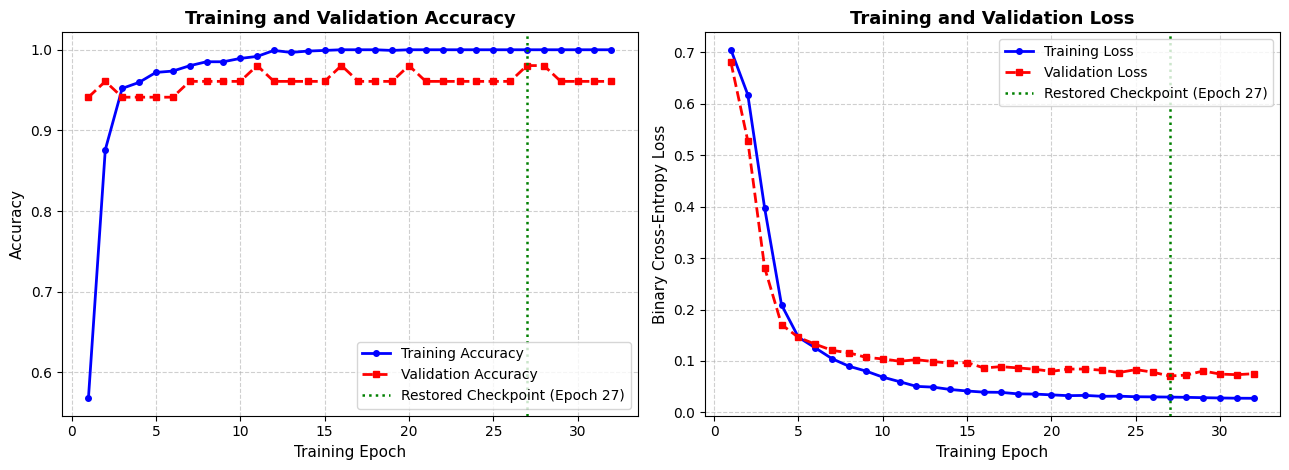

In [5]:
class DeterministicCharTokenizer:
    def __init__(self, char_to_idx):
        self.char_to_idx = char_to_idx
    def texts_to_sequences(self, texts):
        return [[self.char_to_idx[ch] for ch in clean_text(t) if ch in self.char_to_idx] for t in texts]

char_tokenizer = DeterministicCharTokenizer(CHAR_TO_IDX)
with open('tokenizer_char.pkl', 'wb') as handle:
    pickle.dump(char_tokenizer, handle)

def encode_char_sequences(texts, maxlen=MAX_LEN):
    seqs = char_tokenizer.texts_to_sequences(texts)
    return pad_sequences(seqs, maxlen=maxlen, padding='post', truncating='post')

X_train_pad = encode_char_sequences(X_train_clean)
X_val_pad = encode_char_sequences(X_val_clean)
X_test_pad = encode_char_sequences(X_test_clean)

def build_char_cnn(vocab_size=VOCAB_SIZE, embed_dim=50, max_len=MAX_LEN, seed=SEED):
    set_all_seeds(seed)
    inputs = Input(shape=(max_len,), dtype='int32', name="Input_SMS")
    x = Embedding(
        input_dim=vocab_size, output_dim=embed_dim,
        embeddings_regularizer=regularizers.l2(1e-4),
        name="Embedding"
    )(inputs)

    mask = Embedding(
        input_dim=vocab_size, output_dim=1,
        embeddings_initializer='ones',
        trainable=False,
        name="Zero_Padding_Mask"
    )(inputs)
    x = Multiply(name="Masked_Embedding")([x, mask])
    x = SpatialDropout1D(0.2, seed=seed, name="SpatialDropout")(x)

    conv_3 = Conv1D(filters=64, kernel_size=3, activation='relu', kernel_regularizer=regularizers.l2(1e-4), name="Conv1D_3")(x)
    conv_4 = Conv1D(filters=64, kernel_size=4, activation='relu', kernel_regularizer=regularizers.l2(1e-4), name="Conv1D_4")(x)
    conv_5 = Conv1D(filters=64, kernel_size=5, activation='relu', kernel_regularizer=regularizers.l2(1e-4), name="Conv1D_5")(x)

    pool_3 = GlobalMaxPooling1D(name="GMP_3")(conv_3)
    pool_4 = GlobalMaxPooling1D(name="GMP_4")(conv_4)
    pool_5 = GlobalMaxPooling1D(name="GMP_5")(conv_5)

    merged = concatenate([pool_3, pool_4, pool_5], name="Concat_Pools")
    dense = Dense(128, activation='relu', kernel_regularizer=regularizers.l2(1e-4), name="Dense_128")(merged)
    dropout = Dropout(0.5, seed=seed, name="Dropout_05")(dense)
    outputs = Dense(1, activation='sigmoid', name="Sigmoid_Out")(dropout)

    model = Model(inputs=inputs, outputs=outputs, name="Proposed_Char_CNN")
    mask_w = np.ones((vocab_size, 1), dtype=np.float32)
    mask_w[0, 0] = 0.0
    model.get_layer("Zero_Padding_Mask").set_weights([mask_w])

    model.compile(optimizer=Adam(learning_rate=3e-4), loss='binary_crossentropy', metrics=['accuracy'])
    return model

model = build_char_cnn()
early_stopping = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)

history = model.fit(
    X_train_pad, y_train_aug,
    epochs=35,
    batch_size=32,
    validation_data=(X_val_pad, y_val),
    callbacks=[early_stopping],
    shuffle=False,
    verbose=1
)

model.save('char_cnn_spam_model.keras')

epoch_df = pd.DataFrame({
    'Epoch': range(1, len(history.history['loss']) + 1),
    'Train_Loss': history.history['loss'],
    'Train_Acc': history.history['accuracy'],
    'Val_Loss': history.history['val_loss'],
    'Val_Acc': history.history['val_accuracy']
})
best_epoch_idx = int(np.argmin(history.history['val_loss']))
best_epoch_num = best_epoch_idx + 1
epoch_df['Restored_Checkpoint'] = ['YES' if i == best_epoch_idx else 'NO' for i in range(len(epoch_df))]
epoch_df.to_csv('epoch_validation_log.csv', index=False)

val_probs = model.predict(X_val_pad, verbose=0).flatten()
val_preds_05 = (val_probs >= 0.5).astype(int)
reconciled_val_acc = accuracy_score(y_val, val_preds_05)

print("\nPer-epoch validation log:")
print(epoch_df.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
print(f"\nStopped at Epoch {len(epoch_df)} | Restored checkpoint: Epoch {best_epoch_num} | Val Loss: {history.history['val_loss'][best_epoch_idx]:.4f} | Val Acc: {reconciled_val_acc:.4f} ({sum(val_preds_05 == y_val)}/{len(y_val)})")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))
epochs_range = epoch_df['Epoch']

ax1.plot(epochs_range, epoch_df['Train_Acc'], 'b-o', label='Training Accuracy', linewidth=2, markersize=4)
ax1.plot(epochs_range, epoch_df['Val_Acc'], 'r--s', label='Validation Accuracy', linewidth=2, markersize=4)
ax1.axvline(best_epoch_num, color='green', linestyle=':', linewidth=1.8, label=f'Restored Checkpoint (Epoch {best_epoch_num})')
ax1.set_title('Training and Validation Accuracy', fontsize=13, fontweight='bold')
ax1.set_xlabel('Training Epoch', fontsize=11)
ax1.set_ylabel('Accuracy', fontsize=11)
ax1.legend(loc='lower right')
ax1.grid(True, linestyle='--', alpha=0.6)

ax2.plot(epochs_range, epoch_df['Train_Loss'], 'b-o', label='Training Loss', linewidth=2, markersize=4)
ax2.plot(epochs_range, epoch_df['Val_Loss'], 'r--s', label='Validation Loss', linewidth=2, markersize=4)
ax2.axvline(best_epoch_num, color='green', linestyle=':', linewidth=1.8, label=f'Restored Checkpoint (Epoch {best_epoch_num})')
ax2.set_title('Training and Validation Loss', fontsize=13, fontweight='bold')
ax2.set_xlabel('Training Epoch', fontsize=11)
ax2.set_ylabel('Binary Cross-Entropy Loss', fontsize=11)
ax2.legend(loc='upper right')
ax2.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.savefig('fig2_3_training_curves.png', dpi=300)
plt.savefig('fig2_3_training_curves.pdf')
plt.show()

## 6. Holdout Evaluation, Augmentation Ablation Study, and Environment Export
The restored checkpoint is evaluated on the held-out test set ($N = 51$). Five controlled training configurations are then compared across both the proposed Char-CNN and the Word-CNN baseline to isolate the effect of each augmentation component.

In [6]:
test_probs = model.predict(X_test_pad, verbose=0).flatten()
test_preds = (test_probs >= 0.5).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, test_preds).ravel()

print("Holdout Test Set Performance:")
print(f"Confusion Matrix: TP={tp}, FP={fp}, TN={tn}, FN={fn} (N={len(y_test)})")
print(f"Accuracy: {accuracy_score(y_test, test_preds):.4f} | Precision: {precision_score(y_test, test_preds):.4f} | Recall: {recall_score(y_test, test_preds):.4f} | HAM FPR: {fp / (fp + tn):.4f} | F1: {f1_score(y_test, test_preds):.4f}")
print(f"ROC-AUC: {roc_auc_score(y_test, test_probs):.4f} | PR-AUC: {average_precision_score(y_test, test_probs):.4f}\n")

test_spam_raw = df_test[df_test['label'] == 1]['cleaned_text'].tolist()
test_ham_raw = df_test[df_test['label'] == 0]['cleaned_text'].tolist()

X_test_obf_spam = []
for t in test_spam_raw:
    X_test_obf_spam.append(clean_text(apply_obfuscation(t, 'substitution')))
    X_test_obf_spam.append(clean_text(apply_obfuscation(t, 'insertion')))
    X_test_obf_spam.append(clean_text(apply_obfuscation(t, 'vowel_removal')))

X_test_num_ham = []
for t in test_ham_raw:
    for suffix in [" jam 10 ya", " tgl 25 pak", " 15 orang bro", " no 482 nih"]:
        X_test_num_ham.append(clean_text(t + suffix))

X_test_obf_pad = encode_char_sequences(X_test_obf_spam)
X_test_num_ham_pad = encode_char_sequences(X_test_num_ham)

def build_ablation_word_cnn(vocab_cap=5000, max_w=100, seed=SEED):
    set_all_seeds(seed)
    inp = Input(shape=(max_w,))
    x = Embedding(vocab_cap, 50, embeddings_regularizer=regularizers.l2(1e-4))(inp)
    x = SpatialDropout1D(0.2, seed=seed)(x)
    x = Conv1D(64, 3, activation='relu', kernel_regularizer=regularizers.l2(1e-4))(x)
    x = GlobalMaxPooling1D()(x)
    x = Dense(64, activation='relu', kernel_regularizer=regularizers.l2(1e-4))(x)
    out = Dense(1, activation='sigmoid')(Dropout(0.5, seed=seed)(x))
    m = Model(inp, out)
    m.compile(optimizer=Adam(learning_rate=3e-4), loss='binary_crossentropy', metrics=['accuracy'])
    return m

ablation_modes = [
    ('1. Clean Imbalanced (No Aug)', 'clean_imbalanced'),
    ('2. Random Oversampling Only', 'oversample_only'),
    ('3. SPAM Obfuscation Only', 'spam_aug_only'),
    ('4. HAM Numeric Injection Only', 'ham_aug_only'),
    ('5. Full Proposed Strategy', 'full_proposed')
]

ablation_rows = []
for label_name, mode_key in ablation_modes:
    X_tr_m, y_tr_m, _ = generate_training_data(df_train, mode=mode_key, seed=SEED)
    X_tr_m_pad = encode_char_sequences(X_tr_m)

    m_abl = build_char_cnn(seed=SEED)
    m_abl.fit(
        X_tr_m_pad, y_tr_m,
        epochs=35, batch_size=32,
        validation_data=(X_val_pad, y_val),
        callbacks=[EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)],
        shuffle=False, verbose=0
    )

    p_clean = (m_abl.predict(X_test_pad, verbose=0).flatten() >= 0.5).astype(int)
    p_obf = (m_abl.predict(X_test_obf_pad, verbose=0).flatten() >= 0.5).astype(int)
    p_num_ham = (m_abl.predict(X_test_num_ham_pad, verbose=0).flatten() >= 0.5).astype(int)

    w_tok = Tokenizer(num_words=5000, oov_token='<OOV>')
    w_tok.fit_on_texts(X_tr_m)
    X_tr_w = pad_sequences(w_tok.texts_to_sequences(X_tr_m), maxlen=100, padding='post', truncating='post')
    X_va_w = pad_sequences(w_tok.texts_to_sequences(X_val_clean), maxlen=100, padding='post', truncating='post')
    X_te_w = pad_sequences(w_tok.texts_to_sequences(X_test_clean), maxlen=100, padding='post', truncating='post')
    X_obf_w = pad_sequences(w_tok.texts_to_sequences(X_test_obf_spam), maxlen=100, padding='post', truncating='post')
    X_num_w = pad_sequences(w_tok.texts_to_sequences(X_test_num_ham), maxlen=100, padding='post', truncating='post')

    m_w = build_ablation_word_cnn(seed=SEED)
    m_w.fit(
        X_tr_w, y_tr_m,
        epochs=35, batch_size=32,
        validation_data=(X_va_w, y_val),
        callbacks=[EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)],
        shuffle=False, verbose=0
    )

    p_clean_w = (m_w.predict(X_te_w, verbose=0).flatten() >= 0.5).astype(int)
    p_obf_w = (m_w.predict(X_obf_w, verbose=0).flatten() >= 0.5).astype(int)
    p_num_w = (m_w.predict(X_num_w, verbose=0).flatten() >= 0.5).astype(int)

    ablation_rows.append({
        'Configuration': label_name,
        'Train_Rows': len(X_tr_m),
        'CharCNN_Clean_Acc': accuracy_score(y_test, p_clean),
        'CharCNN_Clean_F1': f1_score(y_test, p_clean),
        'CharCNN_Obf_Recall': np.mean(p_obf == 1),
        'CharCNN_Num_HAM_FPR': np.mean(p_num_ham == 1),
        'WordCNN_Clean_Acc': accuracy_score(y_test, p_clean_w),
        'WordCNN_Clean_F1': f1_score(y_test, p_clean_w),
        'WordCNN_Obf_Recall': np.mean(p_obf_w == 1),
        'WordCNN_Num_HAM_FPR': np.mean(p_num_w == 1)
    })

df_ablation = pd.DataFrame(ablation_rows)
df_ablation.to_csv('ablation_study_results.csv', index=False)
print("Ablation Study Summary (Char-CNN vs Word-CNN):")
print(df_ablation.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

with open('requirements.txt', 'w') as req_file:
    req_file.write(
        f"numpy=={np.__version__}\n"
        f"pandas=={pd.__version__}\n"
        f"scikit-learn=={sklearn.__version__}\n"
        f"tensorflow=={tf.__version__}\n"
        f"matplotlib=={matplotlib.__version__}\n"
        f"openpyxl>=3.1.0\n"
        f"seaborn>=0.13.0\n"
    )

Holdout Test Set Performance:
Confusion Matrix: TP=40, FP=1, TN=9, FN=1 (N=51)
Accuracy: 0.9608 | Precision: 0.9756 | Recall: 0.9756 | HAM FPR: 0.1000 | F1: 0.9756
ROC-AUC: 0.9220 | PR-AUC: 0.9691



Ablation Study Summary (Char-CNN vs Word-CNN):
                Configuration  Train_Rows  CharCNN_Clean_Acc  CharCNN_Clean_F1  CharCNN_Obf_Recall  CharCNN_Num_HAM_FPR  WordCNN_Clean_Acc  WordCNN_Clean_F1  WordCNN_Obf_Recall  WordCNN_Num_HAM_FPR
 1. Clean Imbalanced (No Aug)         151             0.9020            0.9412              1.0000               0.9000             0.8039            0.8913              1.0000               1.0000
  2. Random Oversampling Only        1210             0.9216            0.9524              0.9837               0.6750             0.9608            0.9762              0.9593               0.2500
     3. SPAM Obfuscation Only        1210             0.9216            0.9524              0.9919               0.6750             0.9608            0.9756              0.9919               0.2000
4. HAM Numeric Injection Only        1210             0.9412            0.9639              0.9919               0.1750             0.9412            0.9639     